<a href="https://colab.research.google.com/github/HectorChona/Movilidad-urbana-y-relaciona-con-la-productividad-econ-mica/blob/main/S5_ladb_mobility_economy_project_student_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt # importar librerías

In [12]:
# cargar archivos
traffic = pd.read_csv('/content/tomtom_traffic.csv')
eco = pd.read_csv('/content/oecd_city_economy.csv') #completa el código

In [13]:
print("primeras 5 filas de traffic:")
display(traffic.head()) # mostrar las primeras 5 filas de traffic

primeras 5 filas de traffic:


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [14]:
print("primeras 5 filas de traffic:")
display(eco.head())# mostrar las primeras 5 filas de eco

primeras 5 filas de traffic:


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [15]:
traffic.info()# Examinar la estructura de traffic
display(traffic.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


En la estructura del DF traffic, se observa que:
- `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son `object`, pero deberían ser `datetime`. Requieren conversión para poder extraer el año y calcular diferencias de tiempo.
- `JamsCount` es un conteo de embotellamientos, así que debería ser `int`, no `float64`. Su conversión es opcional, porque el promedio que calcularemos será decimal de todos modos.
- *`.info()` muestra 1,004,464 valores no nulos en todas las columnas, por lo que no hay `NaN`. Aun así, verificaré con `isna()` y buscaré celdas vacías o valores atípicos antes de dar por buena la tabla.

In [16]:
eco.info()
display(eco.head(3)) # Examinar la estructura de eco


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, PM2.5 (μg/m³), Popilation (M) actualmente son tipo `object` pero deberian ser `float`
-  La columna `City GDP/capita` contiene puntos como separador de miles y comas como separadores decimales, los cuales deben limpiarse


### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [17]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={
    "Country": "country",
    "City": "city",
    "UpdateTimeUTC": "update_time_utc",
    "JamsDelay": "jams_delay",
    "TrafficIndexLive": "traffic_index_live",
    "JamsLengthInKms": "jams_length_km",
    "JamsCount": "jams_count",
    "TrafficIndexWeekAgo": "traffic_index_week_ago",
    "UpdateTimeUTCWeekAgo": "update_time_utc_week_ago",
    "TravelTimeLivePer10KmsMins": "travel_time_live_10km",
    "TravelTimeHistoricPer10KmsMins": "travel_time_hist_10km",
    "MinsDelay": "mins_delay_10km",
})

# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_km', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_10km', 'travel_time_hist_10km', 'mins_delay_10km'],
      dtype='object')

In [18]:
# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={
    "Year": "year",
    "City": "city",
    "Country": "country",
    "City GDP/capita": "city_gdp_capita",
    "Unemployment %": "unemployment_pct",
    "PM2.5 (μg/m³)": "pm25",
    "Population (M)": "population_m",
})

# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

In [19]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce') #tu código aquí
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce') #tu código aquí

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                    Non-Null Count    Dtype         
---  ------                    --------------    -----         
 0   country                   1004464 non-null  object        
 1   city                      1004464 non-null  object        
 2   update_time_utc           1004464 non-null  datetime64[ns]
 3   jams_delay                1004464 non-null  float64       
 4   traffic_index_live        1004464 non-null  float64       
 5   jams_length_km            1004464 non-null  float64       
 6   jams_count                1004464 non-null  float64       
 7   traffic_index_week_ago    1004464 non-null  float64       
 8   update_time_utc_week_ago  1004464 non-null  datetime64[ns]
 9   travel_time_live_10km     1004464 non-null  float64       
 10  travel_time_hist_10km     1004464 non-null  float64       
 11  mins_delay_10km           1004464 non-null  float6

In [20]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = (eco['city_gdp_capita'].astype(str)
.str.replace('.', '', regex=False)
.str.replace(',', '.', regex=False)
.astype(float))

eco['unemployment_pct'] = (eco['unemployment_pct'].astype(str)
.str.replace('%', '', regex=False)
.str.strip()
.str.replace(',', '.', regex=False)
.astype(float))

eco['pm25'] = (eco['pm25'].astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float))

eco['population_m'] = (eco['population_m'].astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float))


# Calcula la población total en unidades absolutas (Multiplica * 1000000)
# eco['population'] = ...

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     float64
 6   population_m      30 non-null     float64
dtypes: float64(4), int64(1), object(2)
memory usage: 1.8+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [21]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_km,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_10km,travel_time_hist_10km,mins_delay_10km,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [22]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_km,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_10km,travel_time_hist_10km,mins_delay_10km,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7
18,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8
19,2024,salvador,Brazil,8899.0,12.4,15.2,3.9



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [23]:

# Calcular los  promedios de trafico por ciudad, país y año

traffic_city_year_2024 = (traffic_2024
.groupby(['city', 'country', 'year'])
.agg({'jams_delay': 'mean',
      'traffic_index_live': 'mean',
      'jams_length_km': 'mean',
      'jams_count': 'mean',
      'mins_delay_10km': 'mean',
      'travel_time_live_10km': 'mean',
      'travel_time_hist_10km': 'mean',
    })
    .reset_index()
)

# Mostrar resultado
print("Filas:", traffic_city_year_2024.shape[0])
traffic_city_year_2024.head()  # tu código aqui



Filas: 387


,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay_10km,travel_time_live_10km,travel_time_hist_10km
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [24]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False) # tu código aquí

,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay_10km,travel_time_live_10km,travel_time_hist_10km
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Manila en Filipinas con un promedio de tiempo por viaje de 27.13 min


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [25]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city', 'country', 'year', 'jams_delay', 'traffic_index_live',
       'jams_length_km', 'jams_count', 'mins_delay_10km',
       'travel_time_live_10km', 'travel_time_hist_10km']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population_m']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets (inner: solo ciudades y años presentes en ambos)
merged = traffic_2024_small.merge( eco_2024_small, on=['city', 'year'], how='inner')




# Mostrar las primeras 5 filas
#merged.head()

# Unir datasets
#merged = # tu código aquí

# Mostrar las primeras 5 filas
merged.head(5) # tu código aquí

,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay_10km,travel_time_live_10km,travel_time_hist_10km,city_gdp_capita,unemployment_pct,pm25,population_m
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6.1
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11.3
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4.8
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15.4
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3.7



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

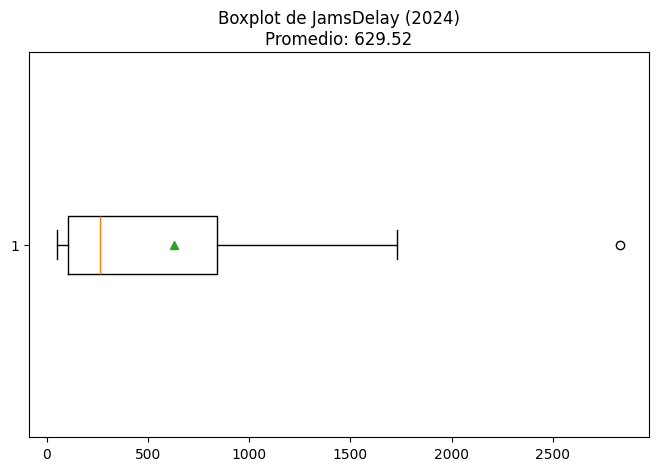

In [26]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
plt.figure(figsize=(8, 5))
plt.boxplot(merged['jams_delay'].dropna(), showmeans=True, vert=False)

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


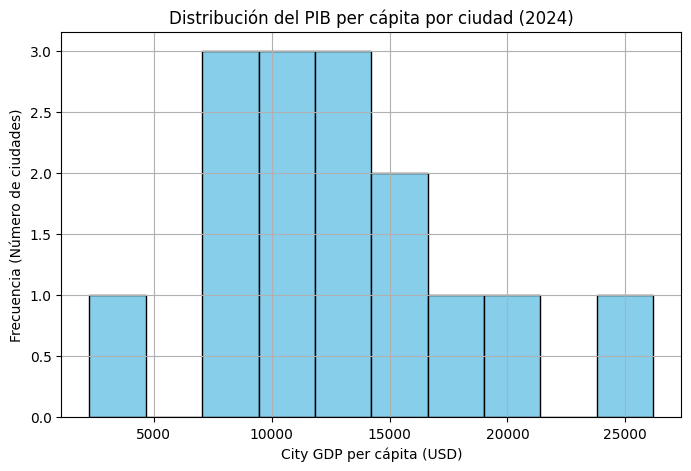

In [27]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)

plt.figure(figsize=(8, 5))
merged['city_gdp_capita'].hist(bins=10, edgecolor='black', color='skyblue')

plt.title('Distribución del PIB per cápita por ciudad (2024)')
plt.xlabel('City GDP per cápita (USD)')
plt.ylabel('Frecuencia (Número de ciudades)')
plt.show()


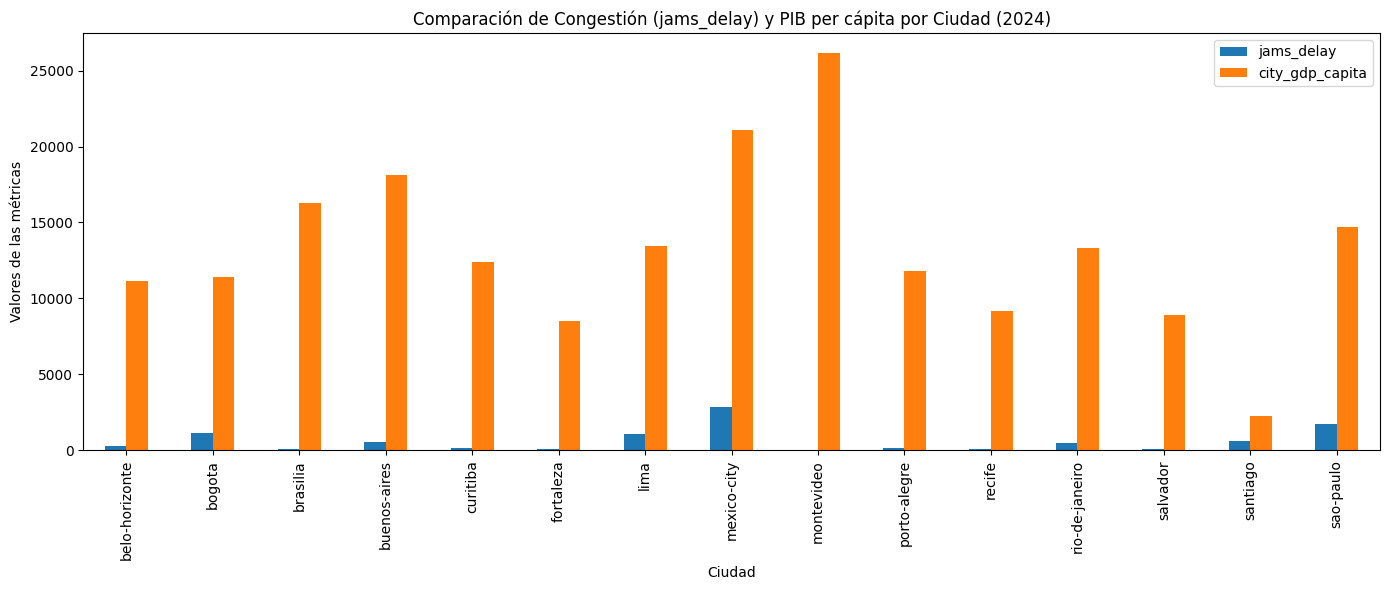

In [28]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(x='city', y=['jams_delay', 'city_gdp_capita'], kind='bar', figsize=(14, 6))

plt.title('Comparación de Congestión (jams_delay) y PIB per cápita por Ciudad (2024)')
plt.xlabel('Ciudad')
plt.ylabel('Valores de las métricas')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios:
Las ciudades con mayor PIB per capita no siempre presentan mayor congestion, por ejemplo Ciudades como Mexico o Sao Paolo tienen alta actividad economica y productiva esto genera un PIB alto pero tambien se observa un considerable nivel de congestion vehicular; por otro lado hay ciudades como Montevideo que presentan un PIB per capita alto pero no tienen alta congestion vehicolar.
Esto nos lleva a concluir que la relación entre la productividad económica y el tráfico urbano es compleja y variable. Contar con un mayor PIB per cápita no implica necesariamente un peor tráfico; esto demuestra que la congestión depende de otros factores estructurales clave, tales como la calidad de la infraestructura vial, las políticas de movilidad y la eficiencia de los sistemas de transporte público en cada ciudad.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [29]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto & objetivo:**  
- Responde la pregunta central del análisis: ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?
- Explica brevemente las variables clave utilizadas y su relevancia para la toma de decisiones.

**Cobertura de datos:**  
- Especifica los años analizados, número de ciudades y países incluidos.

**Metodología (alto nivel):**  
- Describe los procesos principales: limpieza de datos (formatos, estandarización de columnas).
- Explica la agregación por ciudad–año y el uso de una unión INNER para integrar tráfico y economía.
- Menciona las validaciones visuales empleadas (distribuciones, outliers, tendencias generales).

**Hallazgos iniciales:**  
- Resume los patrones más importantes entre índices de tráfico y PIB per cápita.
- Destaca anomalías u outliers que podrían requerir revisión adicional o un análisis más profundo.

**Recomendaciones**  
Aterriza los hallazgos en acciones: ciudades prioritarias, necesidad de validar fuentes, requerimiento de análisis adicionales, o propuestas de inversión.

- ¿Qué ciudad : Bogotá, Lima o Buenos Aires o alguna otra en particular, muestra la mayor correlación significativa entre altos niveles de congestión vehicular y bajos indicadores de productividad económica, sugiriendo ser una ciudad prioritaria para inversión en infraestructura de transporte?



Resumen ejecutivo
Contexto & objetivo:
El presente análisis evalúa cómo la movilidad urbana (medida a través de niveles de congestión, tiempos de viaje y retrasos) se relaciona con la productividad económica expresada mediante el PIB per cápita y el desempleo. El objetivo central del estudio es identificar qué ciudades presentan desequilibrios críticos entre congestión y desarrollo económico, sirviendo como insumo estratégico para orientar futuras inversiones en infraestructura de transporte que aumenten la productividad y el bienestar de la población.

Cobertura de datos:
El análisis se centró de manera exclusiva en el período correspondiente al año 2024, integrando información estandarizada de múltiples ciudades y países a partir de las fuentes globales de TomTom Traffic Index (movilidad en tiempo real) y OECD Cities (indicadores socioeconómicos).

Metodología:
El desarrollo metodológico abarcó la limpieza y validación de tipos de datos, estandarización de nombres de columnas a formato snake_case, y la conversión segura de variables numéricas con caracteres especiales. Posteriormente, se extrajo el componente temporal para filtrar los registros del año 2024, agrupando los datos de tráfico por ciudad y año para obtener promedios anuales representativos. Ambas bases se unificaron mediante un cruce de tipo inner join utilizando city y year como llaves de negocio, validando las distribuciones, presencia de valores atípicos y tendencias generales mediante diagramas de caja, histogramas y gráficos de barras comparativos.

Hallazgos iniciales:
Los resultados visuales y estadísticos demuestran que no existe una relación lineal simple o universal que indique que a mayor PIB per cápita mayor congestión. Mientras que grandes metrópolis como la Ciudad de México o São Paulo experimentan simultáneamente una alta actividad económica y niveles severos de tráfico, se detectaron anomalías positivas como Montevideo, que ostenta un PIB per cápita elevado con índices de congestión considerablemente bajos. En contraste, ciudades como Bogotá y Lima reflejan una presión importante sobre sus redes viales en relación con sus dinámicas de desarrollo.

Recomendaciones:
A partir de los hallazgos, se recomienda priorizar la inversión en infraestructura de transporte urbano en ciudades como Bogotá y Lima, ya que concentran una relación crítica entre alta congestión vehicular, retrasos significativos y desafíos en sus indicadores de productividad. Asimismo, se aconseja complementar este análisis con evaluaciones sobre la cobertura del transporte público masivo y las políticas de gestión de la demanda vial para asegurar que las inversiones maximicen el impacto socioeconómico.
